# KITScenes — Dataset overview

The other notebooks follow one scene. This one looks at all of them: the recording conditions from the scene table,
the splits and the night drives on the city maps, and how much map lies around the vehicle.

**Needs:** `kitscenes[map,viz]` installed as in the README. Section 1 needs no data at all. The other sections draw
the scenes under `DATASET_ROOT` and read only their poses and the city maps, so a download without cameras, lidars
and aerial imagery is enough to see every scene (49 GB, mostly radar, labels and GNSS):

```bash
kitscenes download "$KITSCENES_ROOT" --components none --no-aerial
```

With only the example scene of notebook 01 the notebook runs too, and the figures show that one scene. The figures here show every scene.

In [1]:
import os

import matplotlib.pyplot as plt
import numpy as np

import kitscenes

%matplotlib inline
plt.rcParams["figure.dpi"] = 72  # small figures

DATASET_ROOT = os.environ.get("KITSCENES_ROOT", "/data/kitscenes")  # or an absolute path

from kitscenes.map import Region, SceneMap
from kitscenes.map.origin import CITY_ORIGINS

# lanelet2 notes on the routing graphs of the maps (SceneMap.routing_problems lists them): not shown here
import logging
import warnings

from kitscenes.map import MapProblemWarning

warnings.filterwarnings("ignore", category=MapProblemWarning)
logging.getLogger("kitscenes.map.scene_map").addFilter(lambda record: "routing graph" not in record.getMessage())

## 1. The recording conditions

`kitscenes.scene_table()` holds all 2,079 released scenes, so it describes the whole dataset without a download.
Here it gives the share of recorded hours per split by light, weather (from the cameras), road surface and lidar
generation (`velodyne`: 2025, `hesai`: 2026). The map-change splits are one group. The columns are listed in
`docs/scene_table.md`.

2079 scenes, 11.8 h


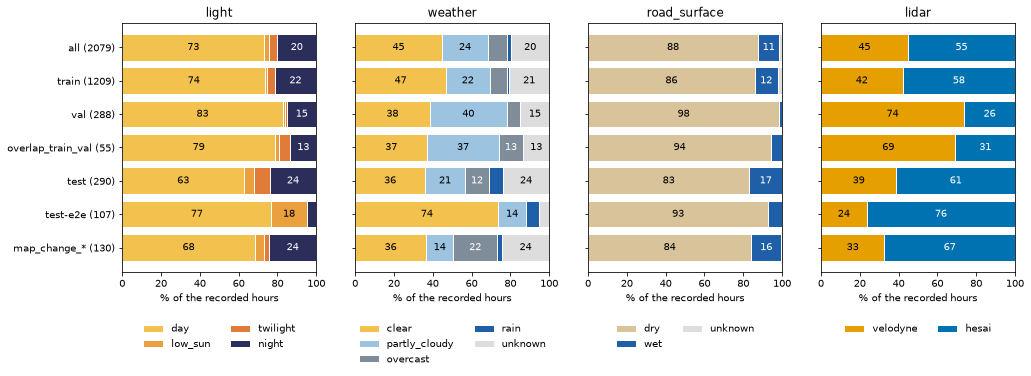

In [2]:
from collections import Counter

import matplotlib.colors as mcolors

table = kitscenes.scene_table()  # every released scene; nothing is read from DATASET_ROOT
COLOURS = {  # the paper's colours
    "light": {"day": "#F2C14E", "low_sun": "#EBA040", "twilight": "#E07B39", "night": "#2B2D5B"},
    "weather": {"clear": "#F2C14E", "partly_cloudy": "#9CC3E0", "overcast": "#7F8C99", "rain": "#1F5FA8",
                "unknown": "#DDDDDD"},
    "road_surface": {"dry": "#D8C39A", "wet": "#1F5FA8", "unknown": "#DDDDDD"},
    "lidar": {"velodyne": "#E69F00", "hesai": "#0072B2"},
}
GROUPS = ["all", "train", "val", "overlap_train_val", "test", "test-e2e", "map_change_*"]
hours = {(g, column): Counter() for g in GROUPS for column in COLOURS}
scenes = Counter()
for info in table.values():
    for g in ("all", "map_change_*" if info.split.startswith("map_change") else info.split):
        scenes[g] += 1
        for column in COLOURS:
            hours[g, column][getattr(info, column)] += info.num_frames / 10 / 3600  # frames at 10 Hz
print(f"{scenes['all']} scenes, {sum(hours['all', 'lidar'].values()):.1f} h")

fig, axes = plt.subplots(1, len(COLOURS), figsize=(16, 4.5), sharey=True)
for ax, (column, colours) in zip(axes, COLOURS.items()):
    left = np.zeros(len(GROUPS))
    for value, colour in colours.items():
        share = np.array([100 * hours[g, column][value] / sum(hours[g, column].values()) for g in GROUPS])
        ax.barh(range(len(GROUPS)), share, left=left, color=colour, edgecolor="white", label=value)
        dark = np.dot(mcolors.to_rgb(colour), [0.299, 0.587, 0.114]) < 0.55
        for y, (x, w) in enumerate(zip(left, share)):
            if w >= 10:
                ax.text(x + w / 2, y, f"{w:.0f}", ha="center", va="center", color="white" if dark else "black")
        left += share
    ax.set(title=column, xlim=(0, 100), xlabel="% of the recorded hours")
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=2, frameon=False)
axes[0].set_yticks(range(len(GROUPS)), [f"{g} ({scenes[g]})" for g in GROUPS])
axes[0].invert_yaxis()
plt.show()

## 2. The scenes on disk and the city maps

`kitscenes.open` takes every split it finds under the root. The dataset root also has the HD maps of the three
cities (`ds.city_maps()`, notebook 04); the poses of every scene of a city are in that city's map frame.

In [3]:
ds = kitscenes.open(DATASET_ROOT)  # every split under the root
print(f"{len(ds)} of the {len(kitscenes.scene_table())} released scenes are on disk, in the splits {list(ds.splits)}")
cities = {city: SceneMap(path, CITY_ORIGINS[city]) for city, path in ds.city_maps().items()}  # each read on first use
print("city maps:", list(cities))

2079 of the 2079 released scenes are on disk, in the splits ['train', 'val', 'test', 'test-e2e', 'overlap_train_val', 'map_change_train', 'map_change_val', 'map_change_test', 'map_change_test-e2e', 'map_change_overlap_train_val']
city maps: ['Frankfurt', 'Karlsruhe', 'Sindelfingen']


## 3. The splits on the city maps

The drives of the scenes on disk, coloured by split, on the city maps. `scene.track` reads only `poses.txt`. The default
split `v2.0.0_default_geosplit` is geographic: the test regions are cut out of the city maps, test scenes are at least
50 m from train and val scenes, and train and val scenes are at least 40 m apart. The test scenes ship no map, but their
poses are in their city's frame too. The test-e2e scenes are left out: their poses are relative to their first pose.

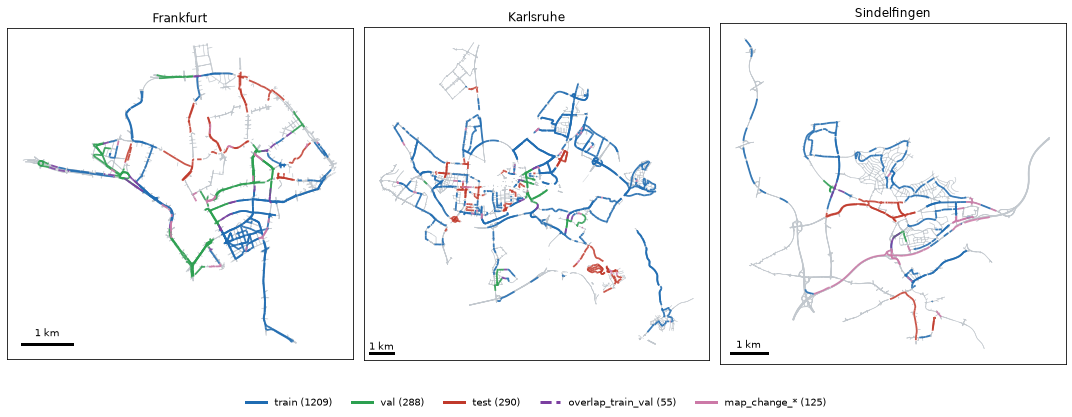

In [4]:
from matplotlib.collections import LineCollection

STYLES = {  # the paper's colour-blind-safe palette
    "train": dict(color="#1F6CB2"),
    "val": dict(color="#2CA050"),
    "test": dict(color="#C0392B"),
    "overlap_train_val": dict(color="#7B3FA0", linestyle="--"),
    "map_change_*": dict(color="#CC79A7"),
}
tracks = {(city, group): [] for city in cities for group in STYLES}
for s in ds:  # all splits on disk
    if s.pose_frame == "local_utm":  # not test-e2e
        group = "map_change_*" if s.split_info.family == "map_change" else s.split
        tracks[s.info.city, group].append(s.track.xyz[:, :2])

UPRIGHT = {"pole", "traffic_sign", "traffic_light", "traffic_light_pedestrians", "traffic_light_bikes"}


def draw_city_map(ax, city):
    """The ground-level lines of a city map in grey, with a 1 km scale bar."""
    roads = [line.points[:, :2] for line in cities[city].lines() if line.type not in UPRIGHT and len(line.points) > 1]
    ax.add_collection(LineCollection(roads, colors="#c2c8ce", linewidths=0.4))
    ax.autoscale()
    (x0, x1), (y0, y1) = ax.get_xlim(), ax.get_ylim()
    ax.plot([x0 + 300, x0 + 1300], [y0 + 300] * 2, "k-", linewidth=3)
    ax.text(x0 + 800, y0 + 450, "1 km", ha="center")
    ax.set(xlim=(x0, x1), ylim=(y0, y1), aspect="equal", xticks=[], yticks=[], title=city)


fig, axes = plt.subplots(1, len(cities), figsize=(15, 5.8), squeeze=False)
for ax, city in zip(axes[0], cities):
    draw_city_map(ax, city)
    for group, style in STYLES.items():
        ax.add_collection(LineCollection(tracks[city, group], linewidths=1.8, alpha=0.85, **style))
counts = {group: sum(len(tracks[city, group]) for city in cities) for group in STYLES}
fig.legend(handles=[plt.Line2D([], [], linewidth=3, label=f"{group} ({counts[group]})", **style)
                    for group, style in STYLES.items()], loc="lower center", ncol=len(STYLES), frameon=False)
fig.tight_layout(rect=(0, 0.06, 1, 1))
plt.show()

## 4. Filtering scenes: the night drives

The scene table describes every scene (city, time, light, weather, road types, speed, ...), and `ds.filter(...)`
keeps the scenes that match, with the criteria of `kitscenes.find_scenes(...)`. `dark=True` selects the real night
scenes: the sun is below −6° for the whole scene. `kitscenes.find_scenes` reads the table that ships with the
package, so it counts the scenes of the whole release, also those not downloaded. The map shows where the night scenes
on disk drive: the poses (10 per second) counted in 100 m cells, on a log scale. Test-e2e scenes are left out again.
The example scene is an afternoon drive, so with only that scene the maps stay empty.

425 night scenes in the release, 425 of them on disk


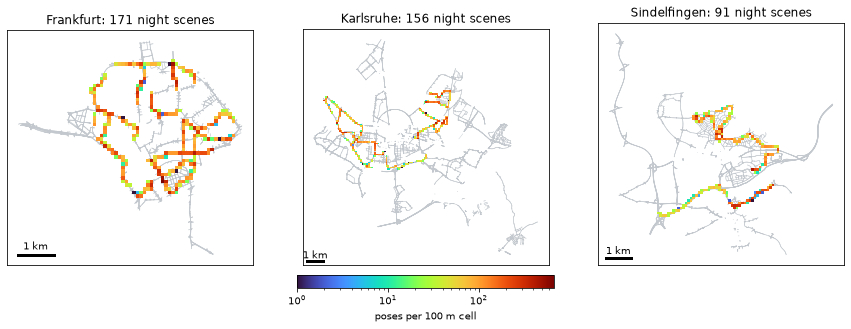

In [5]:
from matplotlib.colors import LogNorm

night = ds.filter(dark=True)
print(f"{len(kitscenes.find_scenes(dark=True))} night scenes in the release, {len(night)} of them on disk")
poses = {city: [s.track.xyz[:, :2] for s in night if s.info.city == city and s.pose_frame == "local_utm"]
         for city in cities}

CELL = 100.0  # m
fig, axes = plt.subplots(1, len(cities), figsize=(15, 5.8), squeeze=False)
grids = []
for ax, city in zip(axes[0], cities):
    draw_city_map(ax, city)
    (x0, x1), (y0, y1) = ax.get_xlim(), ax.get_ylim()
    xy = np.concatenate(poses[city]) if poses[city] else np.zeros((0, 2))
    counts, xs, ys = np.histogram2d(xy[:, 0], xy[:, 1], bins=[np.arange(x0, x1 + CELL, CELL), np.arange(y0, y1 + CELL, CELL)])
    grids.append((ax, xs, ys, np.ma.masked_equal(counts.T, 0)))
    ax.set_title(f"{city}: {len(poses[city])} night scenes")
norm = LogNorm(1, max((g[3].max() for g in grids if g[3].count()), default=10))  # default: no night scene on disk
for ax, xs, ys, counts in grids:
    mesh = ax.pcolormesh(xs, ys, counts, cmap="turbo", norm=norm, zorder=2)
fig.colorbar(mesh, ax=axes[0], orientation="horizontal", fraction=0.04, pad=0.03, shrink=0.4,
             label=f"poses per {CELL:.0f} m cell")
plt.show()

## 5. How much map lies around the vehicle

The map elements around the frames of up to 100 val scenes on disk (one frame per second), counted on the city maps
in two windows around the vehicle: 120 m x 60 m and the 60 m x 30 m of the MapTR preset. `lanes(box)` and `lines(box)`
use the map's spatial index, so this is quick on a city map too. Counted are map elements (lanes and linestrings by
their `type`), not label instances. With only the example scene these are its 22 frames.

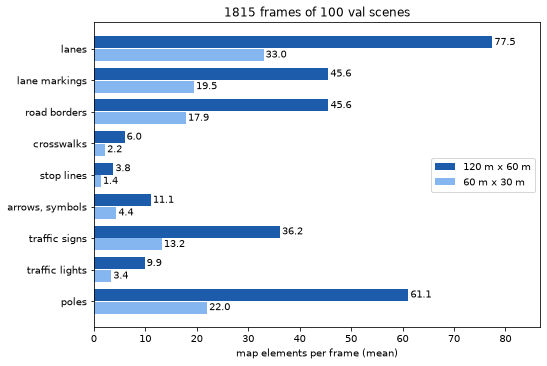

In [6]:
CATEGORIES = {
    "lane markings": {"line_thin", "line_thick", "bike_marking"},
    "road borders": {"curbstone", "road_border", "guard_rail", "jersey_barrier", "fence", "wall"},
    "crosswalks": {"zebra_marking", "pedestrian_marking"},
    "stop lines": {"stop_line"},
    "arrows, symbols": {"arrow", "symbol"},
    "traffic signs": {"traffic_sign"},
    "traffic lights": {"traffic_light", "traffic_light_pedestrians", "traffic_light_bikes"},
    "poles": {"pole"},
}
WINDOWS = {"120 m x 60 m": Region(ahead=60, behind=60, left=30, right=30),
           "60 m x 30 m": Region(ahead=30, behind=30, left=15, right=15)}
counts = {(w, name): [] for w in WINDOWS for name in ["lanes", *CATEGORIES]}
sample = ds.filter(splits="val")[:100]
for s in sample:
    city_map = cities[s.info.city]
    for i in range(0, len(s), 10):
        pose = s[i].pose
        for w, window in WINDOWS.items():
            box = window.around(pose)
            types = [line.type for line in city_map.lines(box)]
            counts[w, "lanes"].append(len(city_map.lanes(box)))
            for name, wanted in CATEGORIES.items():
                counts[w, name].append(sum(t in wanted for t in types))

names = ["lanes", *CATEGORIES]
fig, ax = plt.subplots(figsize=(8, 5.5))
for k, (w, colour) in enumerate(zip(WINDOWS, ["#1c5cab", "#86b6ef"])):
    means = [np.mean(counts[w, name]) for name in names]
    bars = ax.barh(np.arange(len(names)) + 0.4 * k - 0.2, means, height=0.38, color=colour, label=w)
    ax.bar_label(bars, fmt="%.1f", padding=2)
ax.set_yticks(range(len(names)), names)
ax.invert_yaxis()
ax.set(xlabel="map elements per frame (mean)",
       title=f"{len(counts[w, 'lanes'])} frames of {len(sample)} val scenes")
ax.margins(x=0.12)
ax.legend(loc="center right")
plt.show()